In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [20]:
BASE_DIR = Path.cwd().resolve().parent
RAW_DIR = BASE_DIR / "datos" / "raw"
PROCESSED_DIR = BASE_DIR / "datos" / "processed"

lineas = pd.read_csv(PROCESSED_DIR / "lineas_pedido_clean.csv")
pedidos = pd.read_csv(PROCESSED_DIR / "pedidos_clean.csv")
productos = pd.read_csv(PROCESSED_DIR / "productos_clean.csv")
devoluciones = pd.read_csv(PROCESSED_DIR / "devoluciones_clean.csv")

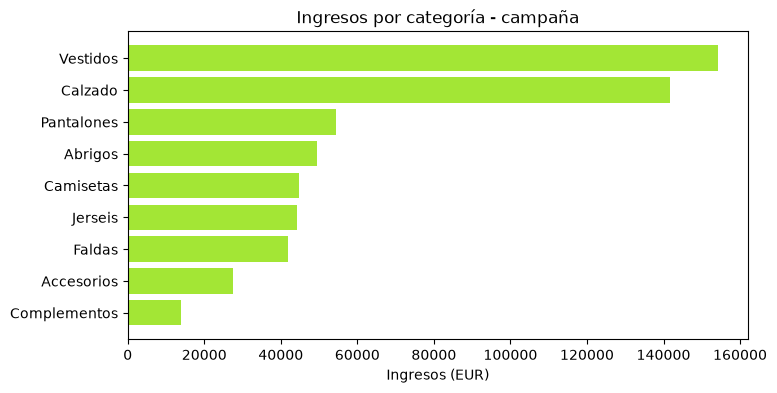

Categoría lider: Vestidos (154,292.26 euros)


In [19]:
# 1. Ingresos por categoría

lp = lineas.merge(pedidos[["pedido_id", "campana_id"]], on="pedido_id", how="left")
lp = lp.merge(productos[["producto_id", "categoria"]], on="producto_id", how="left")
lp["ingreso"] = lp["cantidad"] * lp["precio_unitario"] * (1 - lp["descuento_pct"])
camp = lp[lp["campana_id"] == 1]

ing_cat = camp.groupby("categoria")["ingreso"].sum().sort_values()

plt.figure(figsize=(8, 4))
plt.barh(ing_cat.index, ing_cat.values, color="#a3e635")
plt.title("Ingresos por categoría - campaña")
plt.xlabel("Ingresos (EUR)")
plt.show()

print(f"Categoría lider: {ing_cat.index[-1]} ({ing_cat.iloc[-1]:,.2f} euros)")

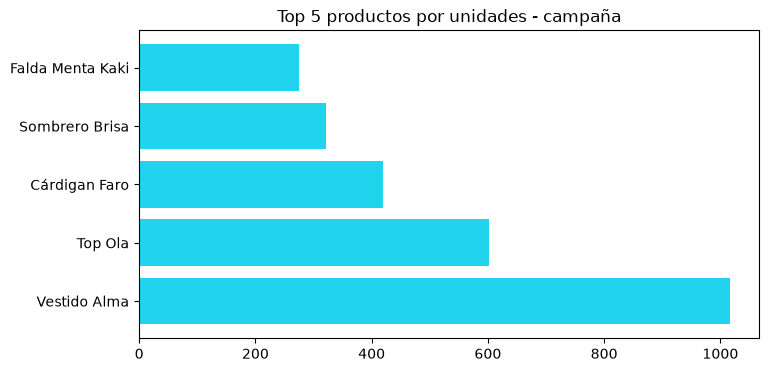

Top 5 productos (unidades) y su tasa de devolución:
  Vestido Alma: 1016 uds, devolución 42.6%
  Top Ola: 602 uds, devolución 19.2%
  Cárdigan Faro: 420 uds, devolución 24.8%
  Sombrero Brisa: 321 uds, devolución 11.9%
  Falda Menta Kaki: 275 uds, devolución 36.4%


In [22]:
# 2. Ventas frente a devoluciones

lp = lineas.merge(pedidos[['pedido_id','campana_id']], on='pedido_id', how='left')
lp = lp.merge(productos[['producto_id','nombre']], on='producto_id', how='left')
devm = devoluciones[devoluciones["linea_id"].isin(lp["linea_id"])]
devj = devm.merge(lp[["linea_id", "nombre"]], on="linea_id", how="left")

camp = lp[lp["campana_id"] == 1]
top5 = camp.groupby("nombre")["cantidad"].sum().sort_values(ascending=False).head(5)
lineas_prod = lp.groupby('nombre').size()
dev_prod = devj.groupby('nombre').size()

plt.figure(figsize=(8, 4))
plt.barh(top5.index, top5.values, color='#22d3ee')
plt.title('Top 5 productos por unidades - campaña')
plt.show()

print("Top 5 productos (unidades) y su tasa de devolución:")
for producto in top5.index:
    # Tasa de devolución del producto, en %: devoluciones / líneas vendidas * 100
    t = dev_prod.get(producto, 0) / lineas_prod[producto] * 100
    print(f"  {producto}: {int(top5[producto])} uds, devolución {t:.1f}%")

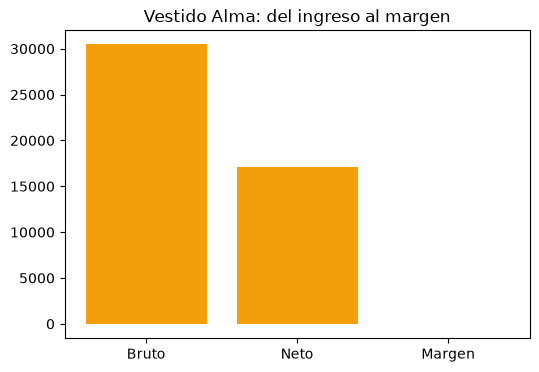

Ingreso bruto del Vestido Alma: 30473.90 EUR
Ingreso neto (tras devoluciones): 17066.59 EUR
Margen neto (tras coste): -60.31 EUR
CIFRA GRANDE PARA CARMEN: el producto estrella deja -60 EUR


In [28]:
# 3. Del ingreso al margen

lp = lineas.merge(pedidos[['pedido_id','campana_id']], on='pedido_id', how='left')
lp = lp.merge(productos[['producto_id','nombre','coste_unitario']], on='producto_id', how='left')
lp['ingreso'] = lp['cantidad'] * lp['precio_unitario'] * (1 - lp['descuento_pct'])

alma = lp[(lp['nombre'] == 'Vestido Alma') & (lp['campana_id'] == 1)]
dev_alma = devoluciones[devoluciones['linea_id'].isin(alma['linea_id'])]
ids_dev = set(dev_alma['linea_id'])
retenidas = alma[~alma['linea_id'].isin(ids_dev)]
devueltas = alma[alma['linea_id'].isin(ids_dev)]

bruto = alma['ingreso'].sum()
# Ingreso neto = bruto menos el ingreso de las líneas devueltas.
neto = bruto - devueltas['ingreso'].sum()
margen = neto - (retenidas['cantidad'] * retenidas['coste_unitario']).sum()

plt.figure(figsize=(6, 4))
plt.bar(['Bruto', 'Neto', 'Margen'], [bruto, neto, margen], color='#f59e0b')
plt.title('Vestido Alma: del ingreso al margen')
plt.show()

print(f"Ingreso bruto del Vestido Alma: {bruto:.2f} EUR")
print(f"Ingreso neto (tras devoluciones): {neto:.2f} EUR")
print(f"Margen neto (tras coste): {margen:.2f} EUR")
print(f"CIFRA GRANDE PARA CARMEN: el producto estrella deja {round(margen)} EUR")

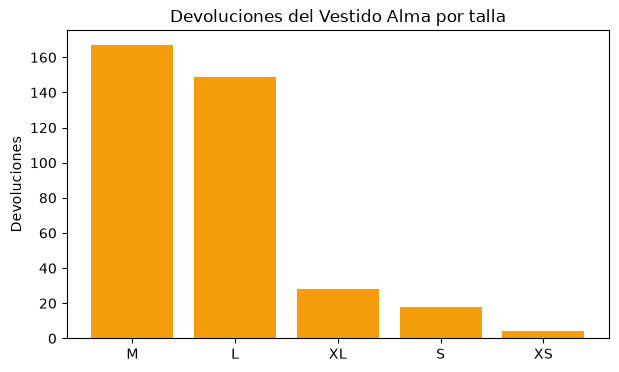

Devoluciones del Alma por talla:
  M: 167 (45.6%)
  L: 149 (40.7%)
  XL: 28 (7.7%)
  S: 18 (4.9%)
  XS: 4 (1.1%)
Las tallas M y L concentran el 86.3% de las devoluciones


In [31]:
# 4. Devoluciones por talla

lp = lineas.merge(productos[['producto_id','nombre']], on='producto_id', how='left')
alma = lp[lp['nombre'] == 'Vestido Alma']
dev_alma = devoluciones[devoluciones['linea_id'].isin(alma['linea_id'])].copy()
dev_alma['talla_norm'] = dev_alma['talla'].astype(str).str.strip().str.upper().str.replace('TALLA ','', regex=False)

# Cuenta cuantas devoluciones hay por talla.
vc = dev_alma['talla_norm'].value_counts()
tot = len(dev_alma)

plt.figure(figsize=(7, 4))
plt.bar(vc.index, vc.values, color='#f59e0b')
plt.title('Devoluciones del Vestido Alma por talla')
plt.ylabel('Devoluciones')
plt.show()

print("Devoluciones del Alma por talla:")
for t in vc.index:
    print(f"  {t}: {vc[t]} ({vc[t]/tot*100:.1f}%)")
ml = vc.get('M', 0) + vc.get('L', 0)
print("Las tallas M y L concentran el %.1f%% de las devoluciones" % (ml/tot*100))

In [32]:
# 5. Dónde sí conviene reinvertir

lp = lineas.merge(pedidos[['pedido_id','campana_id']], on='pedido_id', how='left')
lp = lp.merge(productos[['producto_id','categoria']], on='producto_id', how='left')
lp['ingreso'] = lp['cantidad'] * lp['precio_unitario'] * (1 - lp['descuento_pct'])
camp = lp[lp['campana_id'] == 1].copy()

devm = devoluciones[devoluciones['linea_id'].isin(camp['linea_id'])]
ids_dev = set(devm['linea_id'])
camp['devuelta'] = camp['linea_id'].isin(ids_dev)

bruto_cat = camp.groupby('categoria')['ingreso'].sum()
# Neto = ingreso de las líneas NO devueltas, por categoría.
neto_cat = camp[~camp['devuelta']].groupby('categoria')['ingreso'].sum()

tabla = pd.DataFrame({'bruto': bruto_cat, 'neto': neto_cat})
tabla['retenido_pct'] = tabla['neto'] / tabla['bruto'] * 100
tabla = tabla.sort_values('neto', ascending=False)
for c in tabla.head(4).index:
    print(f"{c}: neto={tabla.loc[c,'neto']:.2f} EUR (retiene {tabla.loc[c,'retenido_pct']:.1f}% del bruto)")

Vestidos: neto=99750.25 EUR (retiene 64.7% del bruto)
Calzado: neto=93101.84 EUR (retiene 65.7% del bruto)
Pantalones: neto=38002.69 EUR (retiene 69.8% del bruto)
Abrigos: neto=36797.82 EUR (retiene 74.3% del bruto)
